<a href="https://colab.research.google.com/github/HatamiM12/Machine-Learning-Training/blob/main/Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [39]:
#Import libreries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, auc
import seaborn as sns

In [40]:
data = load_breast_cancer()
X, y = data.data[:, [2,4]], data.target
print(data.feature_names)

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [41]:
scaler = StandardScaler()
X = scaler.fit_transform(X)
X_bias = np.hstack((X, np.ones((X.shape[0], 1)))) #Adding bias term
X_train, X_test, y_train, y_test = train_test_split(X_bias, y, test_size=0.2, random_state= 42, stratify = y)

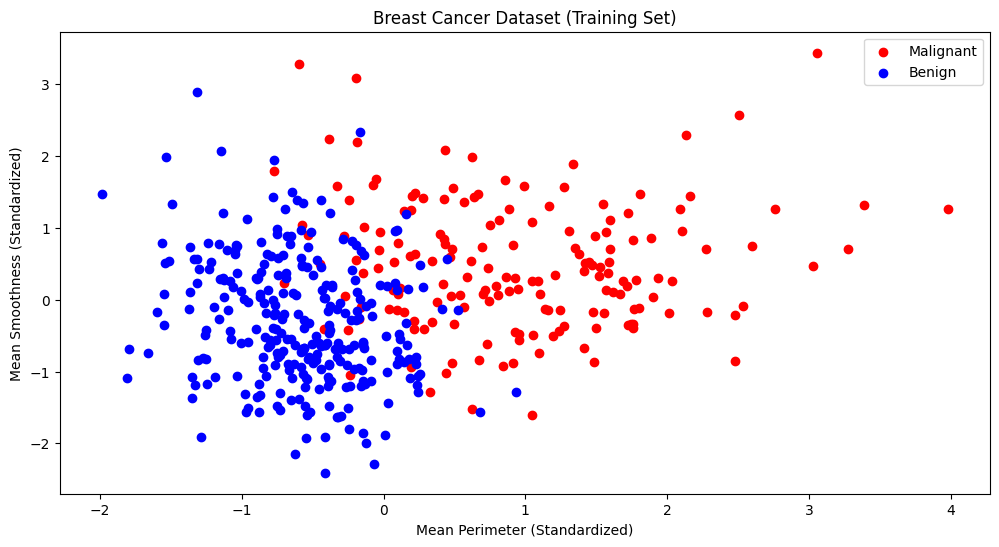

In [42]:
plt.figure(figsize=(12, 6))
plt.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1],
            color='red', label='Malignant')
plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1],
            color='blue', label='Benign')
plt.xlabel('Mean Perimeter (Standardized)')
plt.ylabel('Mean Smoothness (Standardized)')
plt.title('Breast Cancer Dataset (Training Set)')
plt.legend()
plt.show()

In [43]:
# Sigmoid activation function
def sigmoid(z):
  return 1 / (1 + np.exp(-z))

#Compute_loss function
def compute_loss(w, X, y):
  z = X @ w
  prediction = sigmoid(z)
  loss = -np.mean(y * np.log(prediction) + (1 - y) * np.log(1 - prediction))
  return loss

#compute_gradient of the loss weight
def compute_gradient(w, X, y):
  z = X @ w
  prediction = sigmoid(z)
  errors = prediction - y
  gradient = X.T @ errors / len(y)
  return gradient

#Evaluate test accuracy
def test_accuracy(w, X_test, y_test):
  probabilities = sigmoid(X_test @ w)
  predictions = (probabilities > 0.5).astype(int)
  accuracy = np.mean(predictions == y_test)
  return accuracy

In [44]:
# Gradient descent for logistic regression
def gradient_decsent_logistic(X_train, X_test, y_train, y_test, learning_rate=0.1, n_steps=1000, tolerance=1e-6):
  #Initialize weights
  w = np.zeros(X_train.shape[1])
  # Track loss, accuracy, and weights
  loss_history = [compute_loss(w, X_train, y_train)]
  test_accuracy_history = [test_accuracy(w, X_test, y_test)]
  weights_history = [w.copy()]

  #training loop
  for step in range(1, n_steps + 1):
    grad = compute_gradient(w, X_train, y_train)
    w -= learning_rate * grad
    loss = compute_loss(w, X_train, y_train)
    loss_history.append(loss)
    acc = test_accuracy(w, X_test, y_test)
    test_accuracy_history.append(acc)

    if step & 10 == 0:
      weights_history.append(w.copy())
    # Check for convergence
    if np.abs(loss_history[-1] - loss_history[-2]) < tolerance:
      print(f'Converged at step {step}')
      break

    if step % 100 == 0:
      print(f'Step {step}: Loss = {loss:.4f}, Test Accuracy = {acc:.4f}')

  return w, loss_history, test_accuracy_history, weights_history

In [45]:
# Set learning rate and number of steps
learning_rate = 0.05
n_steps = 800

# Train logistic regression model with gradient descent
w_opt, loss_history, test_accuracy_history, weights_history = gradient_decsent_logistic(X_train, X_test, y_train, y_test)
print(f'Optimized weights: {w_opt}')
print(f'Decision rule: {w_opt[0]} * Mean Perimeter + {w_opt[1]} * Mean Smoothness + {w_opt[2]} > 0 : Benign')
print(f'Decision rule: {w_opt[0]} * Mean Perimeter + {w_opt[1]} * Mean Smoothness + {w_opt[2]} < 0 : Malignant')


Step 100: Loss = 0.2900, Test Accuracy = 0.8860
Step 200: Loss = 0.2454, Test Accuracy = 0.8860
Step 300: Loss = 0.2282, Test Accuracy = 0.8860
Step 400: Loss = 0.2192, Test Accuracy = 0.8860
Step 500: Loss = 0.2138, Test Accuracy = 0.8860
Step 600: Loss = 0.2103, Test Accuracy = 0.8860
Step 700: Loss = 0.2079, Test Accuracy = 0.8860
Step 800: Loss = 0.2061, Test Accuracy = 0.8860
Step 900: Loss = 0.2048, Test Accuracy = 0.8947
Step 1000: Loss = 0.2039, Test Accuracy = 0.8860
Optimized weights: [-3.80978107 -1.30521247  0.5926462 ]
Decision rule: -3.809781074132796 * Mean Perimeter + -1.3052124719198706 * Mean Smoothness + 0.59264620312011 > 0 : Benign
Decision rule: -3.809781074132796 * Mean Perimeter + -1.3052124719198706 * Mean Smoothness + 0.59264620312011 < 0 : Malignant


/tmp/ipykernel_2586/1843615407.py:13: RuntimeWarning: invalid value encountered in scalar divide
  plt.axvline(x=-w[2] / w[0], color='green')


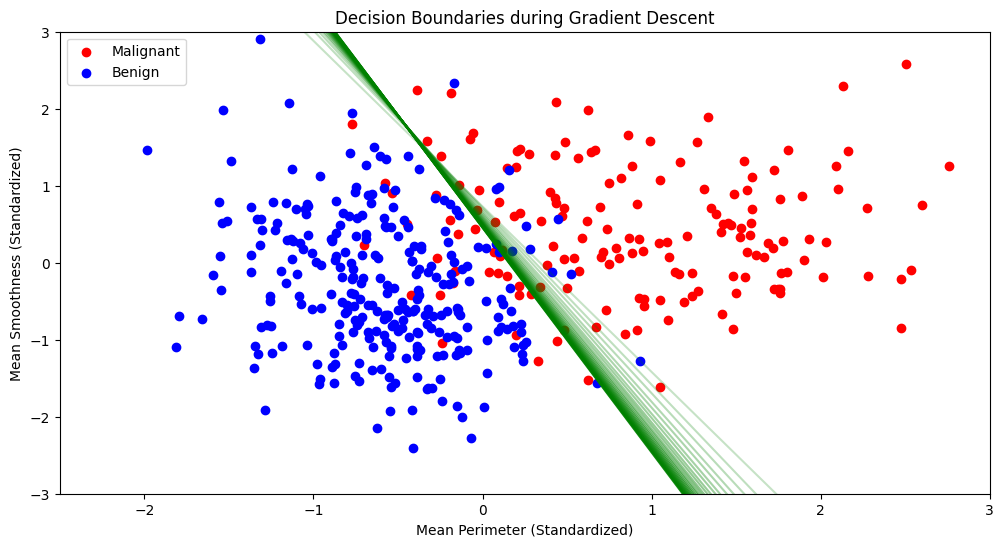

In [46]:
# Plot a single decision boundary for given weights
def plot_decision_boundary(w, X, y, step, total_steps):
    x_values = np.array([X[:, 0].min() - 1, X[:, 0].max() + 1])

    # Compute corresponding y-values for the boundary
    if w[1] != 0:
        y_values = -(w[0] * x_values + w[2]) / w[1]
        # Draw boundary with increasing opacity over steps
        plt.plot(x_values, y_values, color='green',
                 alpha=(0.20 + (step / total_steps) * 0.20))
    else:
        # Vertical line if w[1] == 0
        plt.axvline(x=-w[2] / w[0], color='green')

    plt.legend()


# Plot all decision boundaries throughout training
def plot_decision_boundaries(weights_history, X, y, total_steps):

    plt.figure(figsize=(12, 6))

    # Plot data points by class
    plt.scatter(X[y == 0, 0], X[y == 0, 1], color='red', label='Malignant')
    plt.scatter(X[y == 1, 0], X[y == 1, 1], color='blue', label='Benign')

    # Set plot limits
    plt.xlim(-2.5, 3)
    plt.ylim(-3, 3)

    # Plot decision boundaries for selected training steps
    for i, w in enumerate(weights_history):
        if i % 10 == 0:
            step = i * 10
            plot_decision_boundary(w, X, y, step, total_steps)

    plt.title('Decision Boundaries during Gradient Descent')
    plt.xlabel('Mean Perimeter (Standardized)')
    plt.ylabel('Mean Smoothness (Standardized)')
    plt.show()


plot_decision_boundaries(weights_history, X_train[:, :2], y_train, n_steps)

              precision    recall  f1-score     support
Malignant      0.822222  0.880952  0.850575   42.000000
Benign         0.927536  0.888889  0.907801   72.000000
accuracy       0.885965  0.885965  0.885965    0.885965
macro avg      0.874879  0.884921  0.879188  114.000000
weighted avg   0.888736  0.885965  0.886718  114.000000
Accuracy: 0.8860


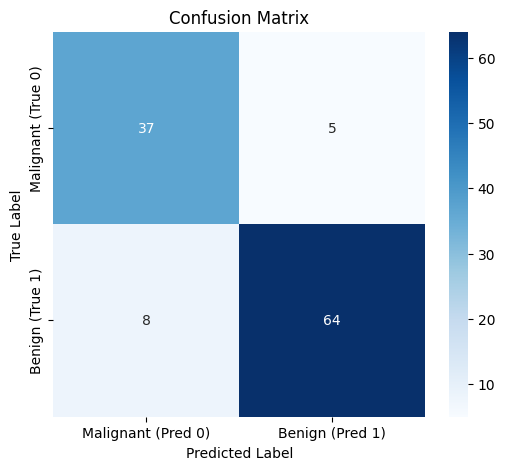

ROC Curve Analysis
Area Under the Curve (AUC): 0.9626


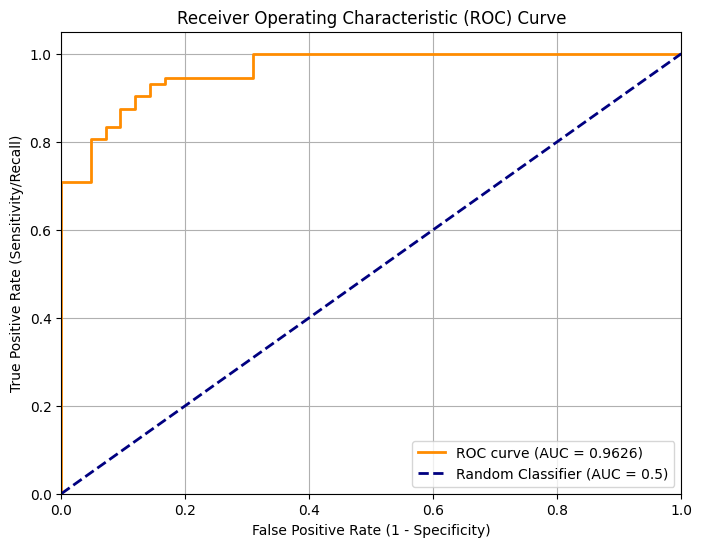

In [53]:
from sklearn.metrics import classification_report, roc_curve, auc, confusion_matrix
import pandas as pd

# Compute model outputs and predictions on validation set
z_test = X_test @ w_opt
probabilities_test = sigmoid(z_test)
predictions_test = (probabilities_test > 0.5).astype(int)

# Generate classification report
report = classification_report(y_test, predictions_test, target_names=['Malignant', 'Benign'], output_dict=True)
df_report = pd.DataFrame(report).transpose()
print(df_report)

# Extract and print overall accuracy
accuracy = report['accuracy']
print(f"Accuracy: {accuracy:.4f}")

# Compute and plot confusion matrix
cm = confusion_matrix(y_test, predictions_test)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Malignant (Pred 0)', 'Benign (Pred 1)'],
            yticklabels=['Malignant (True 0)', 'Benign (True 1)'])
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# Compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, probabilities_test)
roc_auc = auc(fpr, tpr)

print("ROC Curve Analysis")
print(f"Area Under the Curve (AUC): {roc_auc:.4f}")

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2,
         label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--',
         label='Random Classifier (AUC = 0.5)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity/Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()